In [1]:
import numpy as np
import pandas as pd
import os
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=ConvergenceWarning)

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/sample_submission.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/train.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/test.csv


In [2]:
df = pd.read_csv("/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/train.csv")
df.head()

,id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating
0,0,McDonald's,Fast food restaurant,"9814 International Dr, Orlando, FL 32819, Unit...",28.423814,-81.461242,"5,468",11 months ago,"Very nice staff, good place to get all your fa...",5
1,1,McDonald's,Fast food restaurant,"1100 N US Hwy 377, Roanoke, TX 76262, United S...",33.009318,-97.222925,998,10 months ago,"I think the morning shift are one of, if not t...",5
2,2,McDonald's,Fast food restaurant,"490 8th Ave, New York, NY 10001, United States",40.752529,-73.992876,"3,902",a year ago,Horrible! Avoid this place at night. Unsafe. ...,1
3,3,McDonald's,Fast food restaurant,"111 Madison St, Oak Park, IL 60302, United States",41.879656,-87.777913,"1,454",9 months ago,Employees too busy window licking to get any o...,1
4,4,McDonald's,Fast food restaurant,"5725 W Irlo Bronson Memorial Hwy, Kissimmee, F...",28.333508,-81.513738,"5,566",4 years ago,I'm sorry to give only one star. But during ou...,1


# Data Types and Descriptive Statistics

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26500 entries, 0 to 26499
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             26500 non-null  int64  
 1   store_name     26500 non-null  object 
 2   category       26500 non-null  object 
 3   store_address  26500 non-null  object 
 4   latitude       25976 non-null  float64
 5   longitude      25976 non-null  float64
 6   rating_count   26500 non-null  object 
 7   review_time    26500 non-null  object 
 8   review         26500 non-null  object 
 9   rating         26500 non-null  int64  
dtypes: float64(2), int64(2), object(6)
memory usage: 2.0+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,26500.0,13249.500000,7650.035403,0.000000,6624.750000,13249.500000,19874.250000,26499.00000
latitude,25976.0,34.427152,5.336112,25.790295,28.655350,33.931261,40.727401,44.98141
longitude,25976.0,-90.659226,16.588603,-121.995421,-97.792874,-81.471414,-75.399919,-73.45982
rating,26500.0,3.130642,1.615425,1.000000,1.000000,3.000000,5.000000,5.00000


# Missing Values and Duplicates

In [5]:
print ("Missing Values\n")
df.isnull().sum()

Missing Values



id                 0
store_name         0
category           0
store_address      0
latitude         524
longitude        524
rating_count       0
review_time        0
review             0
rating             0
dtype: int64

In [6]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

df = df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")

Number of duplicate rows: 0
Shape after removing duplicates: (26500, 10)


# Graphs

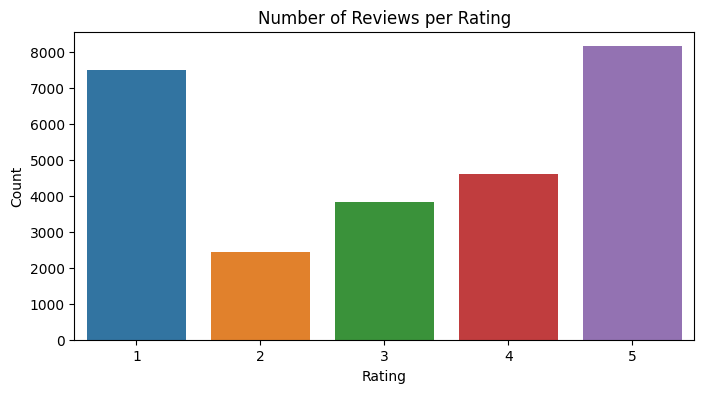

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,4))
sns.countplot(x='rating', data=df)
plt.title('Number of Reviews per Rating')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

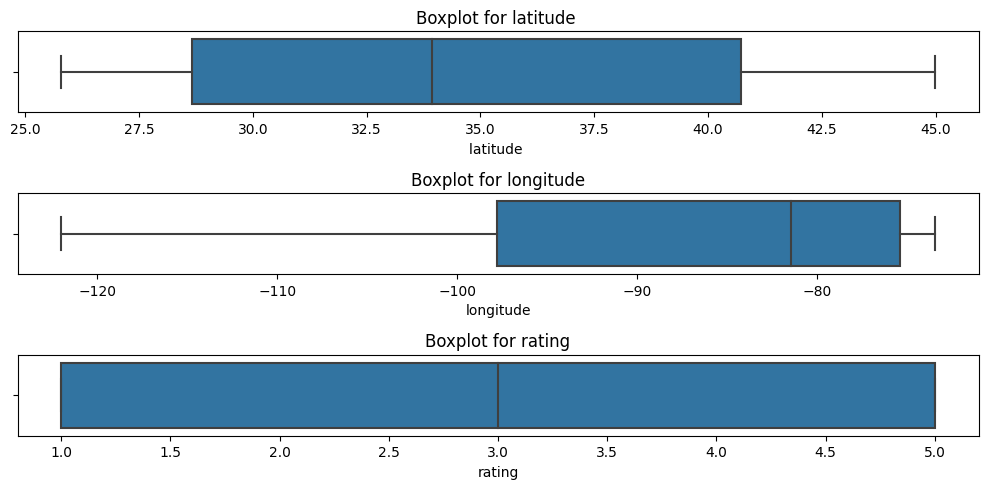

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numerical_cols.remove("id")

plt.figure(figsize=(10, 5))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols), 1, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot for {col}')
plt.tight_layout()
plt.show()

# Outlier detection using IQR
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    print(f"{column} - Outliers detected: {len(outliers)}")
    return df[(df[column] >= lower) & (df[column] <= upper)]

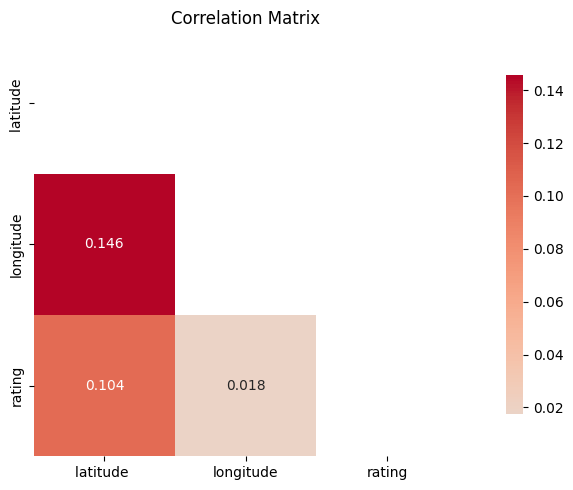

In [9]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numerical_cols.remove('id')
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.3f', cbar_kws={"shrink": .8})
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

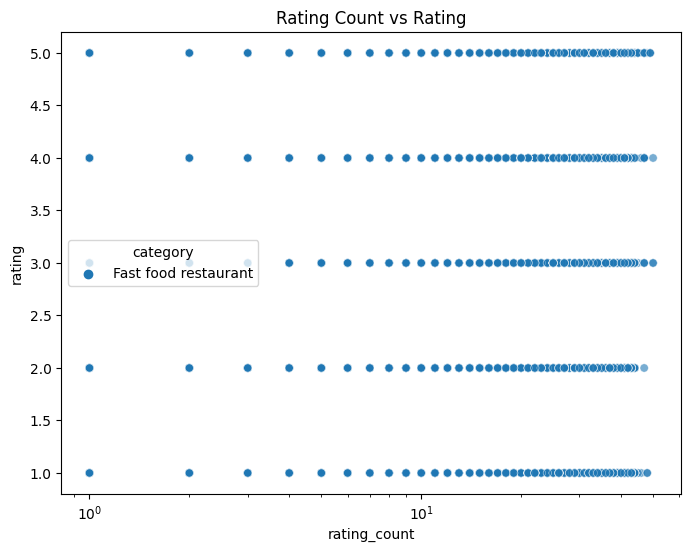

In [10]:
plt.figure(figsize=(8,6))
sns.scatterplot(x="rating_count", y="rating", hue="category", data=df, alpha=0.6)
plt.title("Rating Count vs Rating")
plt.xscale("log")  # log scale for better visibility
plt.show()


# Preprocessing

In [11]:
df = df.rename(columns={"latitude ": "latitude"})

def prep_data(df):
    df['rating_count'] = df['rating_count'].str.replace(',', '').astype(int)
    df['review_length'] = df['review'].apply(len)

    df.drop(columns=['store_name', 'category', 'id', 'store_address'], inplace=True)
    return df

df = prep_data(df)

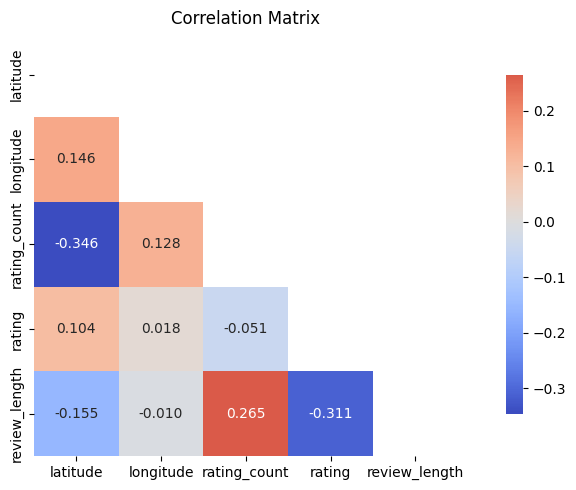

In [12]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.3f', cbar_kws={"shrink": .8})
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [13]:
# Preprocessing Pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import re

X = df.drop(columns=['rating'])
y = df['rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
text_feature = 'review'

numeric_transformer = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

def custom_preprocessor(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text


text_transformer = Pipeline(steps=[
    ('tfidf', TfidfVectorizer(
        preprocessor=custom_preprocessor,
        max_features=800  # limit for speed; can be tuned
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols),
        ('text', text_transformer, text_feature)
    ]
)


X_train_transformed = preprocessor.fit_transform(X_train, y_train)

X_test_transformed = preprocessor.transform(X_test)


# Model Building

## Initial Selection of Model and Comparison of Models

In [14]:
from sklearn.pipeline import FunctionTransformer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                           f1_score, roc_auc_score, classification_report, 
                           confusion_matrix, roc_curve)
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import ExtraTreesClassifier
import time

models = {
    'Logistic Regression': LogisticRegression(random_state=42, multi_class='ovr'),
    'Ridge Classifier': RidgeClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'Linear SVC': LinearSVC(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced'),
    'ExtraTrees Classifier': ExtraTreesClassifier(random_state=42, n_jobs=-1),
}

results = []
model_predictions = {}
# model_probabilities = {}
training_times = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\n1. TRAINING AND EVALUATING MODELS")
print("-" * 40)

for name, model in models.items():
    print(f"\nTraining {name}...")
    
    start_time = time.time()
    
    try:
        model.fit(X_train_transformed, y_train)
        training_time = time.time() - start_time
        training_times[name] = training_time
        
        y_pred = model.predict(X_test_transformed)
        
        model_predictions[name] = y_pred
        
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred ,average='weighted')
        recall = recall_score(y_test, y_pred, average='weighted')
        f1 = f1_score(y_test, y_pred, average='weighted')
        
        cv_scores = cross_val_score(model, X_train_transformed, y_train, 
                                  cv=cv, scoring='accuracy', n_jobs=-1)
        cv_mean = cv_scores.mean()
        cv_std = cv_scores.std()
        
        results.append({
            'Model': name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1 Score': f1,
            'CV F1 Mean': cv_mean,
            'CV F1 Std': cv_std,
            'Training Time (s)': training_time
        })
        
        print(f"F1: {f1:.4f}, Accuracy: {accuracy:.4f}")
        
    except Exception as e:
        print(f"Failed: {str(e)}")
        continue

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("\n2. PERFORMANCE COMPARISON TABLE")
print("-" * 40)
results_df


1. TRAINING AND EVALUATING MODELS
----------------------------------------

Training Logistic Regression...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

F1: 0.6489, Accuracy: 0.6804

Training Ridge Classifier...
Failed: cg() got an unexpected keyword argument 'tol'

Training Decision Tree...
F1: 0.6121, Accuracy: 0.6121

Training Random Forest...
F1: 0.6617, Accuracy: 0.6860

Training Linear SVC...


/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


F1: 0.6923, Accuracy: 0.7115

Training LightGBM...
F1: 0.6557, Accuracy: 0.6511

Training ExtraTrees Classifier...
F1: 0.6627, Accuracy: 0.6879

2. PERFORMANCE COMPARISON TABLE
----------------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std,Training Time (s)
0,Linear SVC,0.711509,0.707052,0.711509,0.692255,0.694292,0.005362,11.513875
1,ExtraTrees Classifier,0.687925,0.718972,0.687925,0.662661,0.674434,0.003778,27.161932
2,Random Forest,0.686038,0.718822,0.686038,0.661681,0.667972,0.002042,61.543878
3,Logistic Regression,0.680377,0.671106,0.680377,0.648859,0.669670,0.005942,4.704473
4,LightGBM,0.651132,0.661778,0.651132,0.655706,0.646368,0.004709,10.392722
5,Decision Tree,0.612075,0.612372,0.612075,0.612093,0.585613,0.007443,5.875673


## Hyperparameter Tuning

In [15]:
from sklearn.model_selection import StratifiedKFold
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV
from xgboost.sklearn import XGBClassifier
from sklearn.metrics import f1_score, roc_auc_score

# Hyperparameter Tuning 3 Model 

model_grids = {
    "LightGBM": (LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1), {
        "max_depth": [10, None],
        'n_estimators': [100, 150],
    }),
    "LinearSVC": (LinearSVC(random_state=42), {
        'max_iter':[500, 1000, 2000],
        'tol': [1e-2, 1e-4],
        'C': [4.5, 1, 3],
    }),
    "ExtraTreesClassifier": (ExtraTreesClassifier(random_state=42, n_jobs=-1), {
        'n_estimators': randint(100, 300),
        'max_depth': [10, 30],
    })
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


results = []
best_models = {}

for name, (model, params) in model_grids.items():
    print(f"\nTraining {name}...")
    if params:
        grid = RandomizedSearchCV(model, params, cv=cv, n_jobs=-1, scoring='accuracy')
        grid.fit(X_train_transformed, y_train)
        best_model = grid.best_estimator_
        print(f"Best Params: {grid.best_params_}")
    else:
        model.fit(X_train_transformed, y_train)
        best_model = model

    preds = best_model.predict(X_test_transformed)
    f1 = f1_score(y_test, preds, average='weighted')
    accuracy = accuracy_score(y_test, preds)
    
    results.append([name, f1, accuracy])
    best_models[name] = best_model

results_df = pd.DataFrame(results, columns=["Model", "f1 Score", "Accuracy"])
results_df = results_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
print("\nModel Comparison:")
results_df


Training LightGBM...
Best Params: {'n_estimators': 150, 'max_depth': None}

Training LinearSVC...


/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Best Params: {'tol': 0.0001, 'max_iter': 2000, 'C': 1}

Training ExtraTreesClassifier...
Best Params: {'max_depth': 30, 'n_estimators': 265}

Model Comparison:


,Model,f1 Score,Accuracy
0,LinearSVC,0.692255,0.711509
1,LightGBM,0.662097,0.659057
2,ExtraTreesClassifier,0.543947,0.598868


# Final Submission

In [16]:
df_test = pd.read_csv("/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/test.csv")


test_ids = df_test['id'].copy()

df_test = prep_data(df_test)

df_test_transformed = preprocessor.transform(df_test)

final_preds = best_models['LinearSVC'].predict(df_test_transformed)

submission_df = pd.DataFrame({
    'id': test_ids,
    'rating': final_preds
})

submission_df.to_csv("submission.csv", index=False)